## Clustering Types Visual Comparison

### Similar Orientation

If clusters are similar shapes but not spherical or in line wiht axis shows advantage of Tied method

Plot saved as gmm_comparison.png


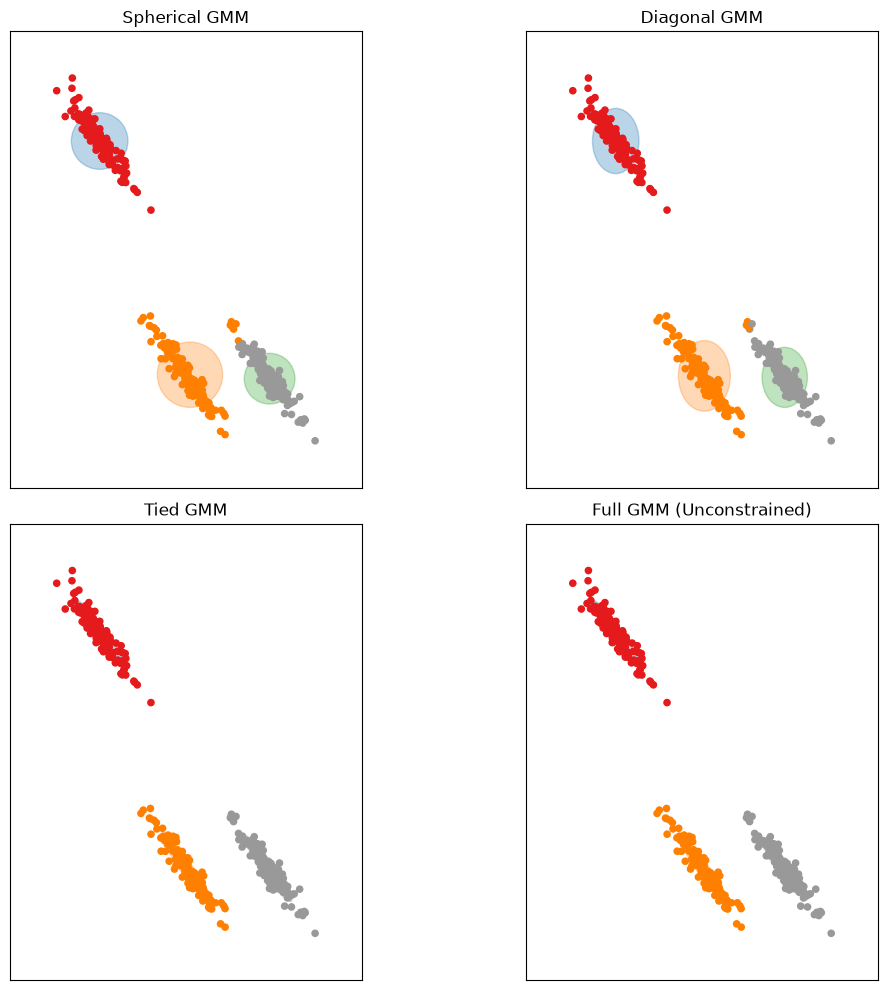

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.mixture import GaussianMixture
from sklearn.datasets import make_blobs

# Generate a single dataset (DST)
np.random.seed(42)
X, y_true = make_blobs(n_samples=400, centers=3, cluster_std=1.0, random_state=42)
# Stretch the data to make it elliptical
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_stretched = np.dot(X, transformation)

# Define the GMM models
models = {
    'Spherical GMM': GaussianMixture(n_components=3, covariance_type='spherical', random_state=42),
    'Diagonal GMM': GaussianMixture(n_components=3, covariance_type='diag', random_state=42),
    'Tied GMM': GaussianMixture(n_components=3, covariance_type='tied', random_state=42),
    'Full GMM (Unconstrained)': GaussianMixture(n_components=3, covariance_type='full', random_state=42)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

def make_ellipses(gmm, ax, covariance_type):
    colors = ['tab:blue', 'tab:orange', 'tab:green']
    for n, color in enumerate(colors):
        if covariance_type == 'full':
            covariances = gmm.covariances_[n][:2, :2]
        elif covariance_type == 'tied':
            covariances = gmm.covariances_[:2, :2]
        elif covariance_type == 'diag':
            covariances = np.diag(gmm.covariances_[n][:2])
        elif covariance_type == 'spherical':
            covariances = np.eye(2) * gmm.covariances_[n]

        v, w = np.linalg.eigh(covariances)
        # eigenvectors are the COLUMNS of w; v[0] (smallest eigenvalue) pairs with w[:, 0]
        angle = np.degrees(np.arctan2(w[1, 0], w[0, 0]))
        v = 2. * np.sqrt(2.) * np.sqrt(v)
        ell = mpl.patches.Ellipse(gmm.means_[n, :2], v[0], v[1], angle=angle, color=color)
        ell.set_clip_box(ax.bbox)
        ell.set_alpha(0.3)
        ax.add_artist(ell)

# Shared axis limits so all four panels are comparable
pad = 2
xlim = (X_stretched[:, 0].min() - pad, X_stretched[:, 0].max() + pad)
ylim = (X_stretched[:, 1].min() - pad, X_stretched[:, 1].max() + pad)

for i, (name, gmm) in enumerate(models.items()):
    gmm.fit(X_stretched)
    y_pred = gmm.predict(X_stretched)

    ax = axes[i]
    ax.scatter(X_stretched[:, 0], X_stretched[:, 1], c=y_pred, s=20, cmap='Set1', zorder=2)
    make_ellipses(gmm, ax, gmm.covariance_type)

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.set_aspect('equal', adjustable='box')  # <-- makes circles actually look circular
    ax.set_title(name)
    ax.set_xticks(())
    ax.set_yticks(())

plt.tight_layout()
plt.savefig('gmm_comparison.png', dpi=150)
print("Plot saved as gmm_comparison.png")

### Variable Cluster Shapes

Shows the limitations of Tied GMM and why full is better.

Plot saved as DST.png


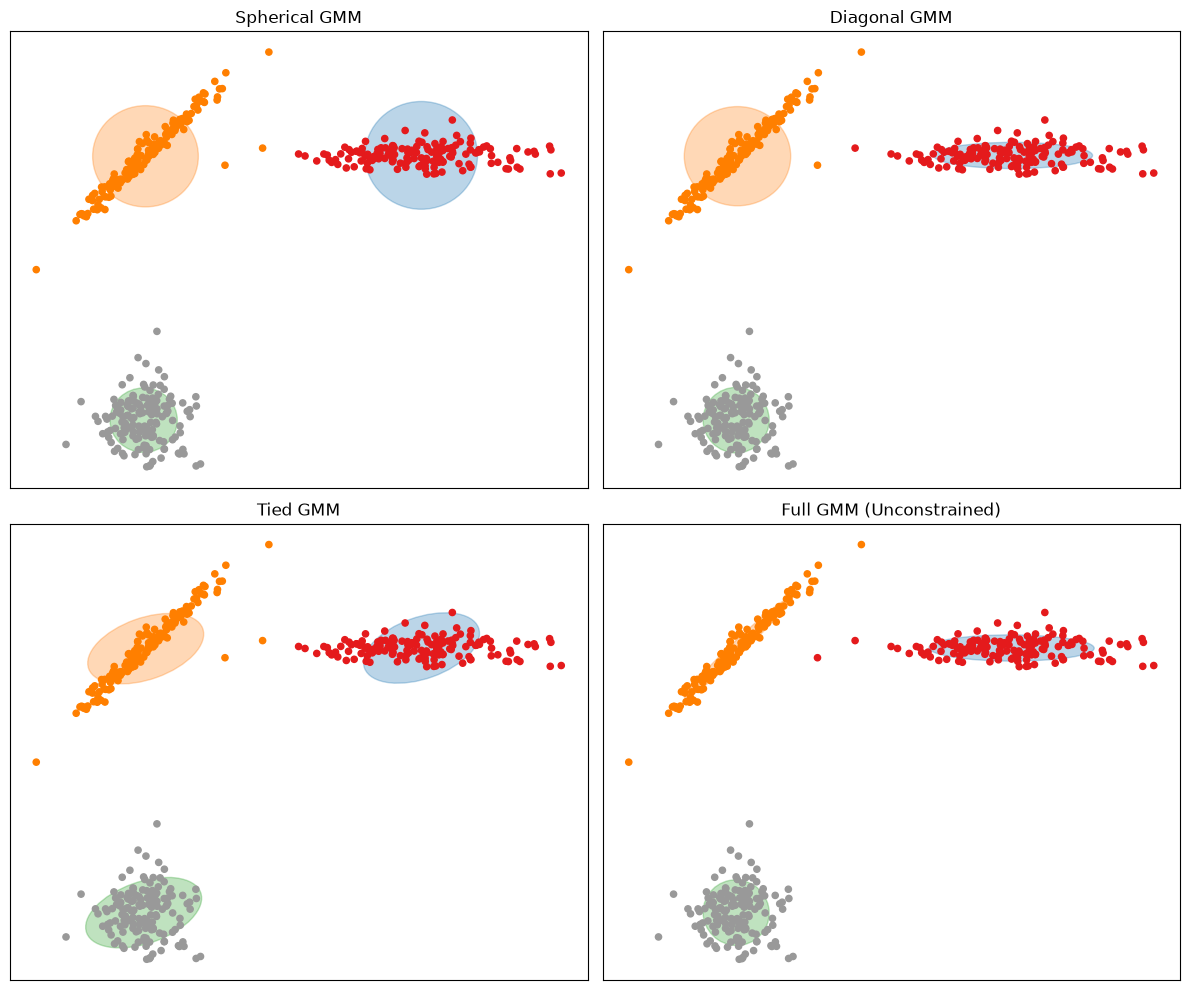

In [ ]:

# Generate a dataset with distinctly shaped and oriented clusters
np.random.seed(42)
X1, _ = make_blobs(n_samples=150, centers=[[-4, -4]], cluster_std=0.7, random_state=42)
X2, _ = make_blobs(n_samples=150, centers=[[4, 4]], cluster_std=0.7, random_state=42)
X3, _ = make_blobs(n_samples=150, centers=[[-4, 4]], cluster_std=0.7, random_state=42)

# Transform each cluster to have DIFFERENT covariances (violating Tied GMM constraint)
# Cluster 1: Remains roughly spherical
# Cluster 2: Stretched heavily horizontally
trans2 = [[2.5, 0.0], [0.0, 0.4]]
X2 = np.dot(X2 - [4, 4], trans2) + [4, 4]

# Cluster 3: Stretched diagonally
trans3 = [[1.0, 1.2], [1.2, 1.0]]
X3 = np.dot(X3 - [-4, 4], trans3) + [-4, 4]

X_varied = np.vstack([X1, X2, X3])

# Define the GMM models
models = {
    'Spherical GMM': GaussianMixture(n_components=3, covariance_type='spherical', random_state=42),
    'Diagonal GMM': GaussianMixture(n_components=3, covariance_type='diag', random_state=42),
    'Tied GMM': GaussianMixture(n_components=3, covariance_type='tied', random_state=42),
    'Full GMM (Unconstrained)': GaussianMixture(n_components=3, covariance_type='full', random_state=42)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

def make_ellipses(gmm, ax, covariance_type):
    colors = ['tab:blue', 'tab:orange', 'tab:green']
    for n, color in enumerate(colors):
        if covariance_type == 'full':
            covariances = gmm.covariances_[n][:2, :2]
        elif covariance_type == 'tied':
            covariances = gmm.covariances_[:2, :2]
        elif covariance_type == 'diag':
            covariances = np.diag(gmm.covariances_[n][:2])
        elif covariance_type == 'spherical':
            covariances = np.eye(gmm.means_.shape[1]) * gmm.covariances_[n]
            
        v, w = np.linalg.eigh(covariances)
        u = w[0] / np.linalg.norm(w[0])
        angle = np.arctan2(u[1], u[0])
        angle = 180 * angle / np.pi
        v = 2. * np.sqrt(2.) * np.sqrt(v)
        ell = mpl.patches.Ellipse(gmm.means_[n, :2], v[0], v[1], angle=180 + angle, color=color)
        ell.set_clip_box(ax.bbox)
        ell.set_alpha(0.3)
        ax.add_artist(ell)

for i, (name, gmm) in enumerate(models.items()):
    # Fit the model
    gmm.fit(X_varied)
    y_pred = gmm.predict(X_varied)
    
    # Plot the clusters
    ax = axes[i]
    scatter = ax.scatter(X_varied[:, 0], X_varied[:, 1], c=y_pred, s=20, cmap='Set1', zorder=2)
    
    # Plot the covariance ellipses
    make_ellipses(gmm, ax, gmm.covariance_type)
    
    ax.set_title(name)
    ax.set_xticks(())
    ax.set_yticks(())

plt.tight_layout()
plt.savefig('DST.png', dpi=150)
print("Plot saved as DST.png")